# Robotics — Assignment 1: Motor Parameter Identification

**CSC 413** · TRIK robot · motors **M3** (right, E3) and **M4** (left, E4) · wheels lifted in all runs

| Data | Date | Files |
|---|---|---|
| Zero drift, square wave, chirp, fine steps ±1…9 % (block programs) | 27 Oct | `motor_data/af*.txt` |
| Step series −100…+100 % in 5 % steps | 22 Oct | `motor_data/week5_steps/` |

The block-program step runs saved only their first 3 s (motor off), so the step series is taken from my 22 Oct recording.

In [1]:
import glob, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint

DATA = "motor_data"
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)
COL = {("M3", "fwd"): "tab:blue", ("M3", "bwd"): "tab:cyan", ("M4", "fwd"): "tab:red", ("M4", "bwd"): "tab:orange"}

## 1. Motor model

$$\frac{d\omega}{dt} = \frac{U}{T_m k_e} - \frac{\omega}{T_m}, \qquad \frac{d\theta}{dt} = \omega$$

| Symbol | Meaning | Unit |
|---|---|---|
| $U$ | motor voltage, $U = \text{PWM}/100 \cdot U_{bat}$ | V |
| $\theta$, $\omega$ | shaft angle and speed | rad, rad/s |
| $\omega_{ss}$ | final speed for a constant $U$ | rad/s |
| $T_m$ | time to reach 63 % of $\omega_{ss}$ | s |
| $k_e$ | volts needed per rad/s: $\omega_{ss} = U/k_e$ | V·s/rad |

**Step response** (from rest): $\omega(t) = \omega_{ss}(1 - e^{-t/T_m})$; integrating once more gives

$$\theta(t) = \omega_{ss}\left(t - T_m + T_m e^{-t/T_m}\right)$$

**Assumptions:** no inductance, friction ∝ ω (so $T_m$ is constant), constant load, constant battery voltage.

## 2. Test signals

| Signal | Settings |
|---|---|
| Step series | ±5…100 %, 2 s per level, both motors |
| Fine steps | ±1…9 %, 2 s on + 1 s off |
| **Square wave** | A = 60 %, P = 1 s, 8 s |
| **Chirp** | A = 60 %, 0.2 → 5 Hz in 8 s |

$T_m$ ≈ 0.05–0.4 s, so $1/(2\pi T_m)$ ≈ 0.4–3 Hz lies inside the chirp range, and P = 1 s is several times $T_m$. Both signals cross zero, and A ≤ 80 %.

## 3. Programs and recorded files

TRIK Studio **block** programs `1_…9_*.qrs` wrote `af111 … af999` (`motor_steps.qrs` = `1_steps_M4.qrs`, `motor_signal.qrs` = `4_square_M4.qrs`). Each line: `angle, time, PWM`.

In [2]:
def load_log(name):
    # block-program log: angle [deg], time [ms], PWM [%] -> t [s from first sample], theta [rad], pwm
    a, t, u = np.loadtxt(os.path.join(DATA, name), delimiter=",", unpack=True)
    return (t - t[0]) / 1000.0, np.radians(a - a[0]), u, t[0]

rows = []
for f in sorted(glob.glob(os.path.join(DATA, "af*.txt"))):
    name = os.path.basename(f)
    t, th, u, t_first = load_log(name)
    dt = np.diff(t) * 1000
    levels = np.unique(u)
    rows.append(dict(file=name, samples=len(t), duration_s=t[-1], dt_mean_ms=dt.mean(), dt_max_ms=dt.max(),
                     pwm_levels=len(levels), pwm_min=levels.min(), pwm_max=levels.max(),
                     angle_range_deg=np.degrees(th.max() - th.min())))
files = pd.DataFrame(rows).set_index("file")
files

,samples,duration_s,dt_mean_ms,dt_max_ms,pwm_levels,pwm_min,pwm_max,angle_range_deg
file,,,,,,,,
af111_steps_M4.txt,100,2.994,30.238,43.694,1,0.0,0.0,0.0
af222_steps_M4_repeat.txt,97,2.985,31.093,44.949,1,0.0,0.0,0.0
af333_steps_M3.txt,94,2.976,31.995,48.479,1,0.0,0.0,0.0
af444_square_M4.txt,201,9.008,45.038,72.830,3,-60.0,60.0,315.0
af555_square_M3.txt,200,9.008,45.269,80.245,3,-60.0,60.0,384.0
af666_chirp_M4.txt,191,8.998,47.355,96.170,84,-60.0,60.0,410.0
af777_chirp_M3.txt,202,9.040,44.978,70.087,83,-60.0,60.0,403.0
af888_deadzone_M4.txt,673,57.260,85.209,2093.251,1,0.0,0.0,2520.0
af999_deadzone_M3.txt,1769,57.284,32.401,68.051,19,-9.0,9.0,2929.0


* **`af111/222/333`:** only the 3 s zero block, no step levels.
* **`af888` (M4 fine steps):** PWM column empty and "motor on" parts missing; speeds are taken from the angle jumps.
* **Sampling:** ≈ 30–45 ms instead of 5 ms (writing the file is slow).
* **Battery:** 12.03–12.12 V on 22 Oct; not noted on 27 Oct.

## 4. Data processing

### 4.1 Loading

Angle → rad, time → s from the first sample.

In [3]:
def load_week5(path):
    hdr = dict(re.findall(r"# (\w+): (\S+)", open(path).read()))
    t, a = np.loadtxt(path, comments="#", unpack=True)
    return hdr, (t - t[0]) / 1000.0, np.radians(a - a[0])

week5 = []
for f in glob.glob(os.path.join(DATA, "week5_steps", "*.txt")):
    hdr, t, th = load_week5(f)
    week5.append(dict(motor=hdr["motor_port"], pwm=int(hdr["pwm_percent"]), t=t, theta=th,
                      u_rest=float(hdr["battery_rest_v"]), u_load=float(hdr["battery_load_v"])))
week5.sort(key=lambda r: (r["motor"], r["pwm"]))
U_BAT = np.mean([r["u_load"] for r in week5])
print(f"{len(week5)} step runs, battery under load {min(r['u_load'] for r in week5):.3f} ... "
      f"{max(r['u_load'] for r in week5):.3f} V, mean U_bat = {U_BAT:.3f} V")
print("sample interval:", np.median(np.diff(week5[0]["t"])) * 1000, "ms")

80 step runs, battery under load 12.025 ... 12.102 V, mean U_bat = 12.076 V
sample interval: 10.000000000000009 ms


### 4.2 Step responses

`curve_fit` of $\theta(t)$ for every level; errors from `pcov`.

In [4]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)

fits = []
for r in week5:
    popt, pcov = optimize.curve_fit(model, r["t"], r["theta"], p0=[8 * np.sign(r["pwm"]), 0.1],
                                    bounds=([-50, 0.005], [50, 2.0]))
    err = np.sqrt(np.diag(pcov))
    r["popt"] = popt
    fits.append(dict(motor=r["motor"], pwm=r["pwm"], omega_ss=popt[0], omega_err=err[0],
                     T_m=popt[1], T_m_err=err[1], U=r["pwm"] / 100 * r["u_load"],
                     rmse_rad=np.sqrt(np.mean((model(r["t"], *popt) - r["theta"]) ** 2))))
fits = pd.DataFrame(fits)
for m in ("M3", "M4"):
    print(f"Motor {m}")
    display(fits[fits.motor == m].drop(columns="motor").set_index("pwm").T.round(3))

Motor M3


pwm,-100,-95,-90,-85,-80,-75,-70,-65,-60,-55,...,55,60,65,70,75,80,85,90,95,100
omega_ss,-15.905,-15.512,-14.826,-14.186,-13.825,-13.475,-12.736,-11.967,-11.815,-11.252,...,11.858,12.369,12.497,13.368,13.985,14.405,14.719,15.353,15.987,16.415
omega_err,0.004,0.004,0.004,0.004,0.006,0.005,0.009,0.006,0.005,0.005,...,0.005,0.004,0.005,0.005,0.004,0.005,0.004,0.004,0.004,0.004
T_m,0.053,0.069,0.084,0.109,0.100,0.129,0.116,0.175,0.207,0.225,...,0.222,0.204,0.186,0.163,0.137,0.129,0.108,0.086,0.068,0.044
T_m_err,0.000,0.000,0.000,0.000,0.000,0.000,0.001,0.001,0.000,0.001,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
U,-12.090,-11.485,-10.892,-10.254,-9.661,-9.077,-8.463,-7.858,-7.254,-6.649,...,6.642,7.246,7.850,8.454,9.057,9.661,10.276,10.881,11.460,12.064
rmse_rad,0.030,0.029,0.027,0.023,0.039,0.027,0.058,0.033,0.023,0.023,...,0.022,0.021,0.026,0.027,0.025,0.028,0.028,0.026,0.029,0.031


Motor M4


pwm,-100,-95,-90,-85,-80,-75,-70,-65,-60,-55,...,55,60,65,70,75,80,85,90,95,100
omega_ss,-15.040,-14.507,-13.720,-13.026,-12.698,-12.286,-11.533,-10.681,-10.458,-9.868,...,10.313,10.945,11.167,12.155,12.980,13.487,13.872,14.801,15.725,16.318
omega_err,0.004,0.003,0.004,0.004,0.003,0.006,0.007,0.004,0.004,0.009,...,0.004,0.004,0.005,0.005,0.005,0.005,0.006,0.005,0.004,0.004
T_m,0.044,0.054,0.071,0.099,0.105,0.085,0.085,0.148,0.158,0.091,...,0.174,0.170,0.167,0.140,0.113,0.097,0.081,0.076,0.053,0.046
T_m_err,0.000,0.000,0.000,0.000,0.000,0.001,0.001,0.000,0.000,0.001,...,0.000,0.000,0.001,0.001,0.000,0.000,0.000,0.000,0.000,0.000
U,-12.077,-11.473,-10.869,-10.254,-9.651,-9.048,-8.463,-7.850,-7.246,-6.642,...,6.635,7.238,7.850,8.445,9.048,9.661,10.243,10.846,11.448,12.064
rmse_rad,0.027,0.022,0.027,0.023,0.021,0.040,0.050,0.024,0.023,0.063,...,0.022,0.021,0.028,0.032,0.029,0.033,0.041,0.034,0.030,0.029


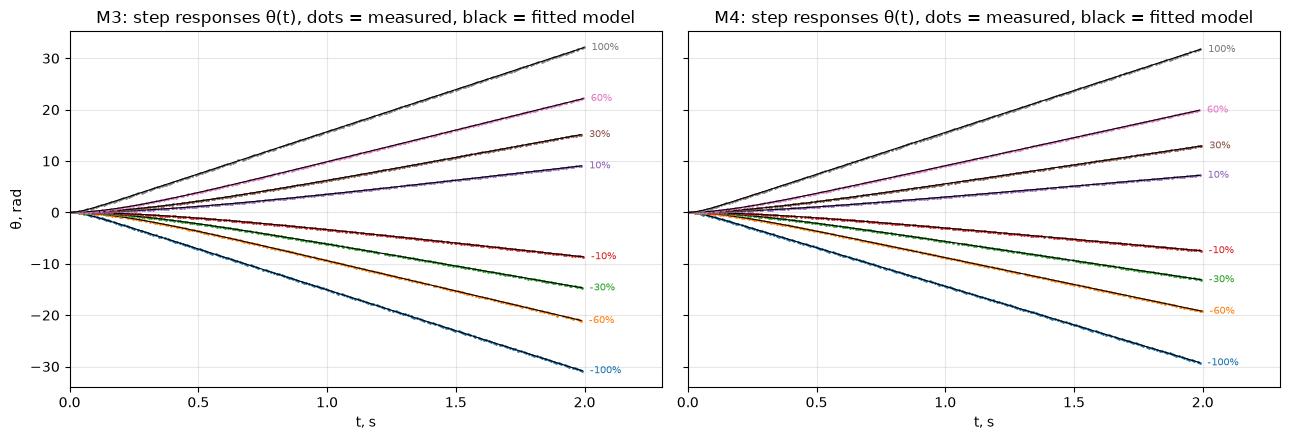

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
show = [-100, -60, -30, -10, 10, 30, 60, 100]
for ax, m in zip(axes, ("M3", "M4")):
    for r in week5:
        if r["motor"] == m and r["pwm"] in show:
            l, = ax.plot(r["t"], r["theta"], ".", ms=2)
            ax.plot(r["t"], model(r["t"], *r["popt"]), "k-", lw=0.8)
            ax.text(r["t"][-1] + 0.03, r["theta"][-1], f"{r['pwm']}%", fontsize=7, color=l.get_color(), va="center")
    ax.set_title(f"{m}: step responses θ(t), dots = measured, black = fitted model")
    ax.set_xlabel("t, s"); ax.set_xlim(0, 2.3)
axes[0].set_ylabel("θ, rad")
plt.tight_layout(); plt.show()

*Figure 1. Step responses (dots) and fitted model (black). Each single step fits well (RMSE ≈ 0.03 rad).*

### 4.3 Speed and $T_m$ versus PWM

Line fitted over 10–70 % for each direction; $k_e = U_{bat}/(100 \cdot \text{slope})$.

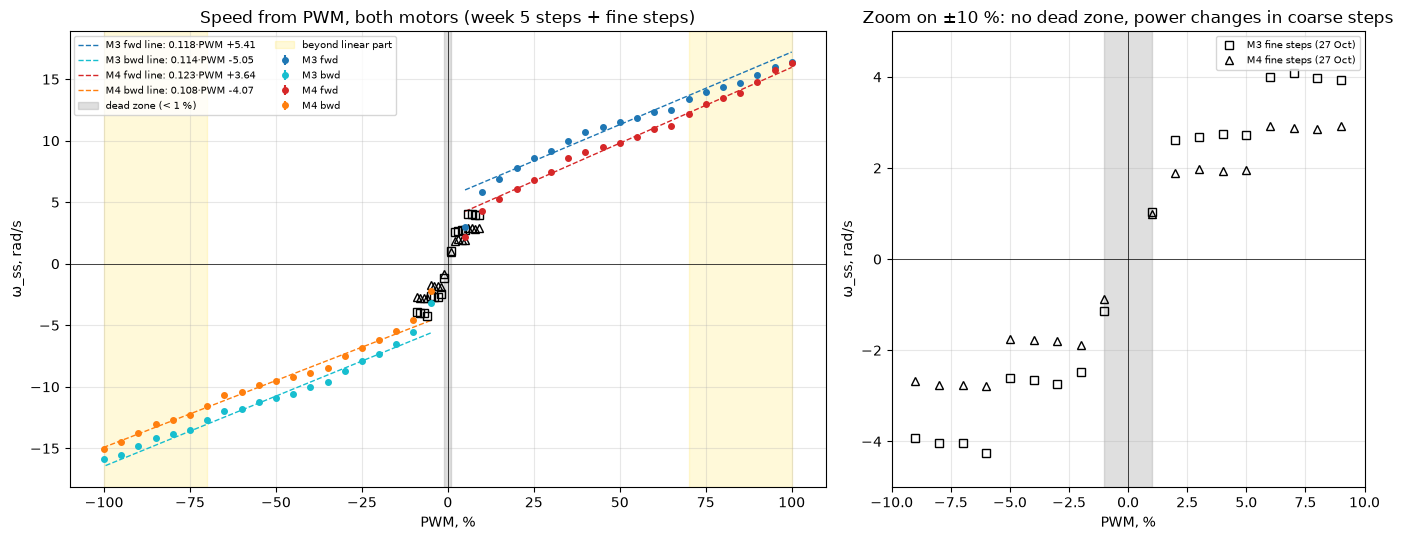

In [6]:
LIN = (10, 70)
lines = {}
for m in ("M3", "M4"):
    d = fits[fits.motor == m]
    for side, sgn in (("fwd", 1), ("bwd", -1)):
        q = d[(sgn * d.pwm >= LIN[0]) & (sgn * d.pwm <= LIN[1])]
        slope, icpt = np.polyfit(q.pwm, q.omega_ss, 1)
        lines[(m, side)] = dict(slope=slope, intercept=icpt, k_e=U_BAT / (100 * slope),
                                T_m_mean=d[sgn * d.pwm > 0].T_m.mean(), T_m_std=d[sgn * d.pwm > 0].T_m.std())

# fine steps: M3 complete; M4 from the angle jump across each 2 s "motor on" gap (PWM not logged)
fine = []
t, th, u, _ = load_log("af999_deadzone_M3.txt")
for lv in range(-9, 10):
    k = (u == lv) & (lv != 0)
    if k.sum() > 3:
        s = k & (t > t[k][0] + 1.0)           # last second of the level = steady speed
        fine.append(dict(motor="M3", pwm=lv, omega=np.polyfit(t[s], th[s], 1)[0]))
t, th, u, _ = load_log("af888_deadzone_M4.txt")
gaps = np.where(np.diff(t) > 1.0)[0]
for g, lv in zip(gaps, [l for l in range(-9, 10) if l != 0]):
    fine.append(dict(motor="M4", pwm=lv, omega=(th[g + 1] - th[g]) / (t[g + 1] - t[g])))   # mean incl. start-up
fine = pd.DataFrame(fine)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})
for (m, side), L in lines.items():
    sgn = 1 if side == "fwd" else -1
    d = fits[(fits.motor == m) & (sgn * fits.pwm > 0)]
    ax.errorbar(d.pwm, d.omega_ss, yerr=d.omega_err, fmt="o", ms=4, color=COL[(m, side)], label=f"{m} {side}")
    x = np.array([sgn * 5, sgn * 100])
    ax.plot(x, L["slope"] * x + L["intercept"], "--", color=COL[(m, side)], lw=1,
            label=f"{m} {side} line: {L['slope']:.3f}·PWM {L['intercept']:+.2f}")
for m, mk in (("M3", "s"), ("M4", "^")):
    d = fine[fine.motor == m]
    for a in (ax, ax2):
        a.plot(d.pwm, d.omega, mk, color="k", mfc="none", ms=6, label=f"{m} fine steps (27 Oct)" if a is ax2 else None)
for a in (ax, ax2):
    a.axvspan(-1, 1, color="grey", alpha=0.25, label="dead zone (< 1 %)" if a is ax else None)
    a.axhline(0, color="k", lw=0.5); a.axvline(0, color="k", lw=0.5)
    a.set_xlabel("PWM, %"); a.set_ylabel("ω_ss, rad/s")
ax.axvspan(70, 100, color="gold", alpha=0.15); ax.axvspan(-100, -70, color="gold", alpha=0.15, label="beyond linear part")
ax.set_title("Speed from PWM, both motors (week 5 steps + fine steps)")
ax.legend(fontsize=7, ncol=2); ax2.set_xlim(-10, 10); ax2.set_ylim(-5, 5)
ax2.set_title("Zoom on ±10 %: no dead zone, power changes in coarse steps"); ax2.legend(fontsize=7)
plt.tight_layout(); plt.show()

*Figure 2. Speed vs PWM. Both motors turn at ±1 %, so the dead zone is < 1 %. Right: at low PWM the speed changes in steps (TRIK power resolution ≈ 4 %).*

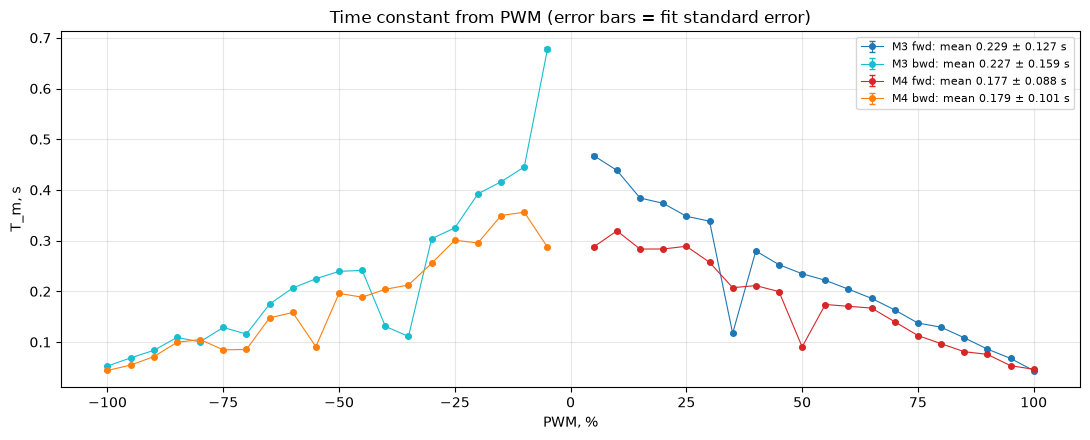

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for (m, side), L in lines.items():
    sgn = 1 if side == "fwd" else -1
    d = fits[(fits.motor == m) & (sgn * fits.pwm > 0)]
    ax.errorbar(d.pwm, d.T_m, yerr=d.T_m_err, fmt="o-", ms=4, lw=0.8, capsize=2, color=COL[(m, side)],
                label=f"{m} {side}: mean {L['T_m_mean']:.3f} ± {L['T_m_std']:.3f} s")
ax.set_xlabel("PWM, %"); ax.set_ylabel("T_m, s"); ax.set_title("Time constant from PWM (error bars = fit standard error)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

*Figure 3. $T_m$ vs PWM. **$T_m$ is not constant**: ≈ 0.3–0.7 s at low PWM, ≈ 0.2 s at 50 %, ≈ 0.05 s at 100 %.*

In [8]:
par = pd.DataFrame([dict(motor=m, direction=side, slope_rad_s_per_pct=L["slope"], intercept_rad_s=L["intercept"],
                         k_e=L["k_e"], T_m_mean=L["T_m_mean"]) for (m, side), L in lines.items()]).set_index(["motor", "direction"])
par

slope_rad_s_per_pct  intercept_rad_s    k_e  T_m_mean
motor direction                                                       
M3    fwd                      0.118            5.409  1.024     0.229
      bwd                      0.114           -5.055  1.059     0.227
M4    fwd                      0.123            3.641  0.980     0.177
      bwd                      0.108           -4.068  1.114     0.179

### 4.4 Complex signal: model vs motor

The logged PWM is held between samples (zero-order hold) and fed to the model.

| Model | Parameters |
|---|---|
| **A** | $k_e$ and mean $T_m$ from the steps |
| **A + dead zone** | A with $u = 0$ for $|PWM| < 1\,\%$ |
| **C** | gains and $T_m$ refitted on the square wave (to test the model itself) |

Fit % $= 100\,(1 - \|y - \hat y\| / \|y - \bar y\|)$. Measured speed = `np.gradient`, plotted with a 3-sample moving average.

In [9]:
def wss_A(u, m, deadzone=0.0):
    side = "fwd" if u >= 0 else "bwd"
    if abs(u) < deadzone or u == 0:
        return 0.0, lines[(m, side)]["T_m_mean"]
    d = fits[(fits.motor == m) & (np.sign(fits.pwm) == np.sign(u)) & (abs(fits.pwm) >= LIN[0]) & (abs(fits.pwm) <= LIN[1])]
    s0 = np.sum(d.pwm * d.omega_ss) / np.sum(d.pwm ** 2)          # line through the origin
    return s0 * u, lines[(m, side)]["T_m_mean"]

def wss_B(u, m):
    d = fits[fits.motor == m].sort_values("pwm")
    if u == 0:
        return 0.0, np.interp(0, d.pwm, d.T_m)
    return np.interp(u, d.pwm, d.omega_ss), np.interp(u, d.pwm, d.T_m)

def simulate(t_log, u_log, law):
    # odeint with the logged PWM held between samples (zero-order hold)
    def motor(state, t):
        speed, angle = state
        k = max(np.searchsorted(t_log, t, "right") - 1, 0)
        w_ss, T_m = law(u_log[k])
        return np.array([(w_ss - speed) / T_m, speed])
    return odeint(motor, [0.0, 0.0], t_log, hmax=0.002)

def fit_pct(y, yh):
    return 100 * (1 - np.linalg.norm(y - yh) / np.linalg.norm(y - np.mean(y)))

def smooth(x, n=3):
    return np.convolve(x, np.ones(n) / n, mode="same")

runs = {"square M4": ("af444_square_M4.txt", "M4"), "square M3": ("af555_square_M3.txt", "M3"),
        "chirp M4": ("af666_chirp_M4.txt", "M4"), "chirp M3": ("af777_chirp_M3.txt", "M3")}
meas = {}
for key, (f, m) in runs.items():
    t, th, u, _ = load_log(f)
    meas[key] = dict(t=t, th=th, u=u, w=np.gradient(th, t), m=m)

# model C: refit s_fwd, s_bwd, T_m on each motor's square wave
refit = {}
for key in ("square M4", "square M3"):
    d = meas[key]
    law = lambda p: (lambda u: ((p[0] if u > 0 else p[1]) * u, p[2]))
    res = optimize.least_squares(lambda p: simulate(d["t"], d["u"], law(p))[:, 0] - d["w"],
                                 [0.16, 0.16, 0.15], bounds=([0.01, 0.01, 0.01], [1, 1, 1]))
    refit[d["m"]] = res.x
    print(f"model C, {d['m']}: s_fwd = {res.x[0]:.4f}, s_bwd = {res.x[1]:.4f} rad/s per %, T_m = {res.x[2]:.3f} s"
          f"  ->  ω at ±60 %: {60*res.x[0]:.2f} / {-60*res.x[1]:.2f} rad/s")

laws = {"A": lambda m: (lambda u: wss_A(u, m)),
        "A + dead zone": lambda m: (lambda u: wss_A(u, m, deadzone=1.0)),
        "C (refit on square)": lambda m: (lambda u: ((refit[m][0] if u > 0 else refit[m][1]) * u, refit[m][2]))}
metrics, sims = [], {}
for key, d in meas.items():
    for name, law in laws.items():
        y = simulate(d["t"], d["u"], law(d["m"]))
        sims[(key, name)] = y
        metrics.append(dict(run=key, model=name, angle_fit_pct=fit_pct(d["th"], y[:, 1]),
                            angle_rmse_rad=np.sqrt(np.mean((d["th"] - y[:, 1]) ** 2)),
                            speed_fit_pct=fit_pct(d["w"], y[:, 0]),
                            speed_rmse_rad_s=np.sqrt(np.mean((d["w"] - y[:, 0]) ** 2))))
metrics = pd.DataFrame(metrics).set_index(["run", "model"])
metrics.round(2)

model C, M4: s_fwd = 0.1571, s_bwd = 0.1532 rad/s per %, T_m = 0.113 s  ->  ω at ±60 %: 9.43 / -9.19 rad/s


model C, M3: s_fwd = 0.1703, s_bwd = 0.1686 rad/s per %, T_m = 0.134 s  ->  ω at ±60 %: 10.22 / -10.12 rad/s


angle_fit_pct  angle_rmse_rad  speed_fit_pct  \
run       model                                                               
square M4 A                            42.64            0.90          71.10   
          A + dead zone                42.64            0.90          71.10   
          C (refit on square)          76.44            0.37          83.13   
square M3 A                            -4.37            1.97          67.62   
          A + dead zone                -4.37            1.97          67.62   
          C (refit on square)          66.03            0.64          80.83   
chirp M4  A                            40.67            0.90          57.63   
          A + dead zone                40.67            0.90          57.63   
          C (refit on square)         -26.97            1.92          60.86   
chirp M3  A                           -47.75            2.17          61.98   
          A + dead zone               -47.75            2.17          61.98   
          C (refit on square)          28.62            1.05          64.29   

                               speed_rmse_rad_s  
run       model                                  
square M4 A                                1.90  
          A + dead zone                    1.90  
          C (refit on square)              1.11  
square M3 A                                2.19  
          A + dead zone                    2.19  
          C (refit on square)              1.30  
chirp M4  A                                1.51  
          A + dead zone                    1.51  
          C (refit on square)              1.40  
chirp M3  A                                1.43  
          A + dead zone                    1.43  
          C (refit on square)              1.34

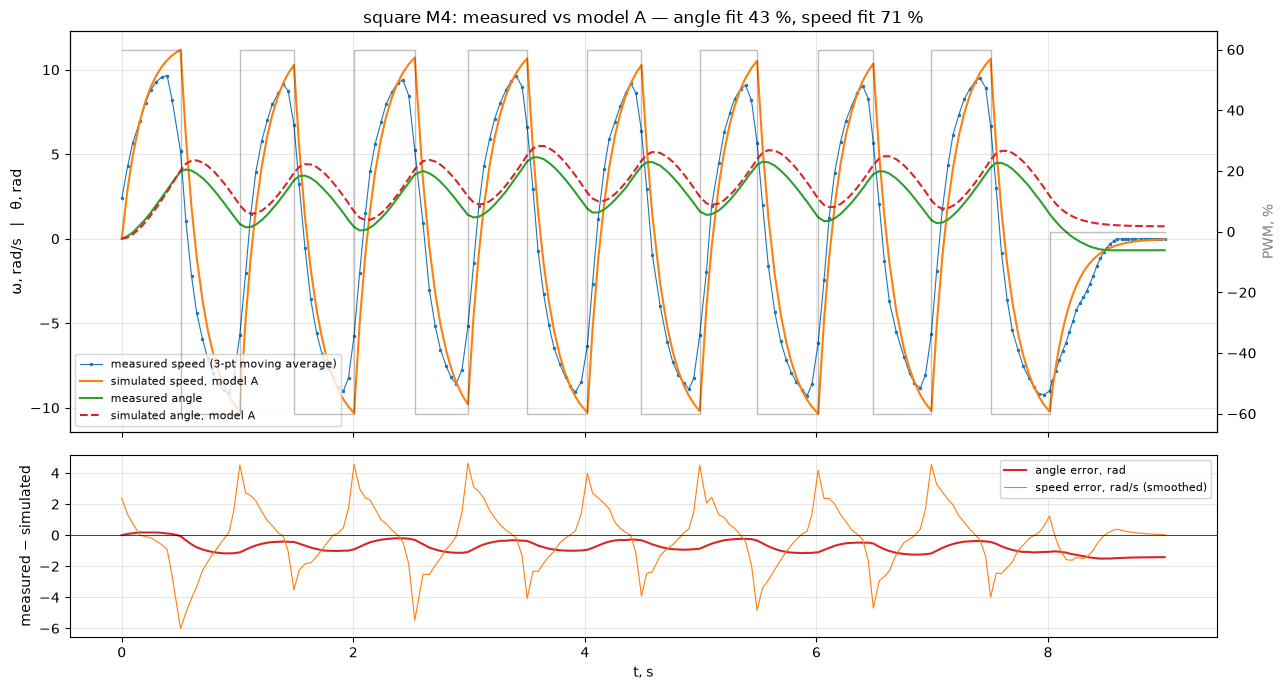

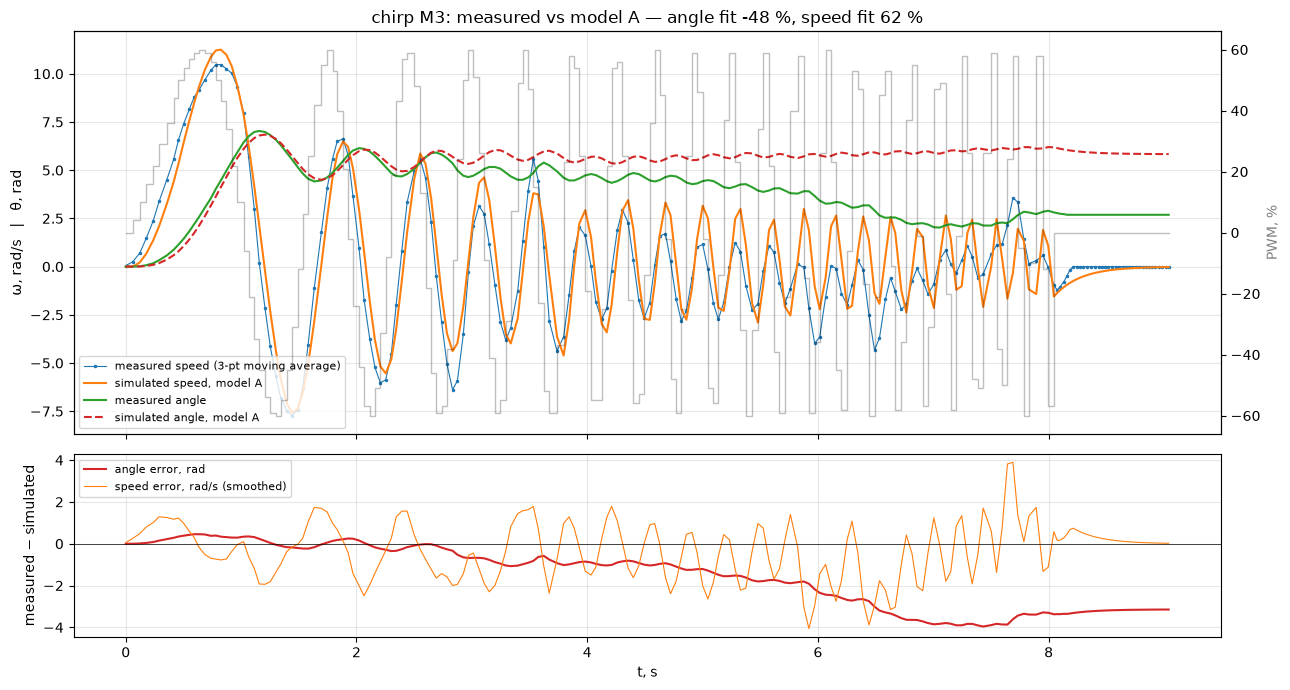

In [10]:
def compare_plot(key, name):
    d, y = meas[key], sims[(key, name)]
    fig, (ax, axe) = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
    ax.plot(d["t"], smooth(d["w"]), ".-", ms=3, lw=0.8, color="tab:blue", label="measured speed (3-pt moving average)")
    ax.plot(d["t"], y[:, 0], color="tab:orange", label=f"simulated speed, model {name}")
    ax.plot(d["t"], d["th"], color="tab:green", lw=1.5, label="measured angle")
    ax.plot(d["t"], y[:, 1], "--", color="tab:red", lw=1.5, label=f"simulated angle, model {name}")
    ax.set_ylabel("ω, rad/s   |   θ, rad")
    a2 = ax.twinx(); a2.step(d["t"], d["u"], "k", where="post", alpha=0.25, lw=1); a2.set_ylabel("PWM, %", color="grey"); a2.grid(False)
    f = metrics.loc[(key, name)]
    ax.set_title(f"{key}: measured vs model {name} — angle fit {f.angle_fit_pct:.0f} %, speed fit {f.speed_fit_pct:.0f} %")
    ax.legend(fontsize=8, loc="lower left")
    axe.plot(d["t"], d["th"] - y[:, 1], color="tab:red", label="angle error, rad")
    axe.plot(d["t"], smooth(d["w"]) - y[:, 0], color="tab:orange", lw=0.8, label="speed error, rad/s (smoothed)")
    axe.axhline(0, color="k", lw=0.5); axe.set_xlabel("t, s"); axe.set_ylabel("measured − simulated"); axe.legend(fontsize=8)
    plt.tight_layout(); plt.show()

compare_plot("square M4", "A")
compare_plot("chirp M3", "A")

*Figures 4–5. Model A vs measurement, with the error below. The model is too fast because the battery was lower on 27 Oct, and the angle error grows over time. (The measured speed seems to turn slightly early only because `np.gradient` uses the next sample.)*

**Chirp frequency response:** peak |ω| / input voltage for each half-cycle, compared with $1/(k_e\sqrt{1 + (2\pi f T_m)^2})$.

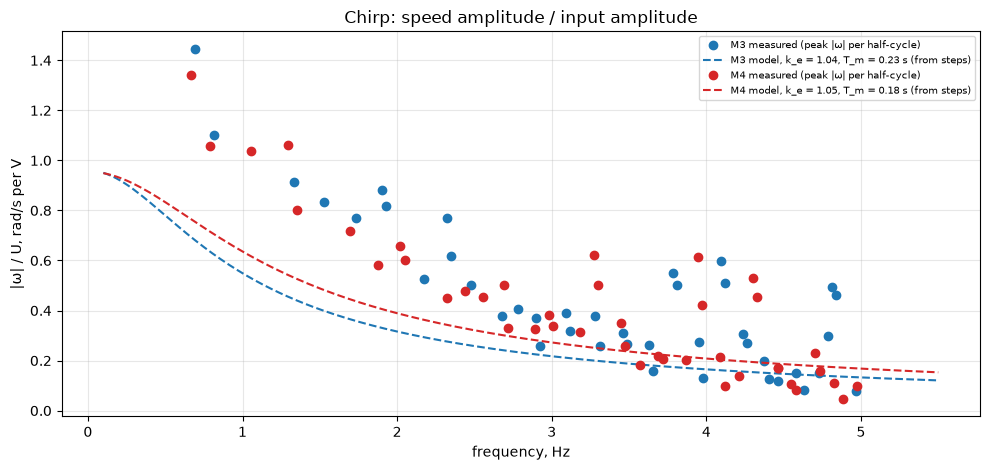

In [11]:
A, F0, F1, T_CH = 60, 0.2, 5.0, 8.0
fig, ax = plt.subplots(figsize=(10, 4.8))
ff = np.linspace(0.1, 5.5, 200)
for key, c in (("chirp M3", "tab:blue"), ("chirp M4", "tab:red")):
    d = meas[key]; m = d["m"]
    on = d["t"] <= T_CH
    zc = np.where(np.diff(np.sign(d["u"][on])) != 0)[0]
    f_pk, g_pk = [], []
    for a, b in zip(zc[:-1], zc[1:]):
        seg = slice(a + 1, b + 2)
        i = np.argmax(np.abs(smooth(d["w"])[seg])) + a + 1
        f_pk.append(F0 + (F1 - F0) * d["t"][i] / T_CH); g_pk.append(abs(smooth(d["w"])[i]) / (A / 100 * U_BAT))
    ax.plot(f_pk, g_pk, "o", color=c, label=f"{m} measured (peak |ω| per half-cycle)")
    ke_m = np.mean([lines[(m, s)]["k_e"] for s in ("fwd", "bwd")]); tm_m = np.mean([lines[(m, s)]["T_m_mean"] for s in ("fwd", "bwd")])
    ax.plot(ff, 1 / (ke_m * np.sqrt(1 + (2 * np.pi * ff * tm_m) ** 2)), "--", color=c,
            label=f"{m} model, k_e = {ke_m:.2f}, T_m = {tm_m:.2f} s (from steps)")
ax.set_xlabel("frequency, Hz"); ax.set_ylabel("|ω| / U, rad/s per V"); ax.set_title("Chirp: speed amplitude / input amplitude")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()

*Figure 6. The measured points fall like a first-order lag. Below 2 Hz the model gives about half the measured value, because the 10–70 % line has a large offset (3.6–5.4 rad/s). Above 3 Hz the points scatter (only 4–8 samples per period).*

## 5. Artifact analysis

In [12]:
# 1. Forward vs backward asymmetry
asym = []
for m in ("M3", "M4"):
    f, b = lines[(m, "fwd")], lines[(m, "bwd")]
    w60f, w60b = wss_B(60, m)[0], -wss_B(-60, m)[0]
    asym.append(dict(motor=m, slope_fwd=f["slope"], slope_bwd=b["slope"], slope_diff_pct=100 * (f["slope"] - b["slope"]) / b["slope"],
                     omega60_fwd=w60f, omega60_bwd=w60b, omega60_diff_pct=100 * (w60f - w60b) / w60b,
                     T_m_fwd=f["T_m_mean"], T_m_bwd=b["T_m_mean"], T_m_diff_pct=100 * (f["T_m_mean"] - b["T_m_mean"]) / b["T_m_mean"],
                     square_s_fwd=refit[m][0], square_s_bwd=refit[m][1], square_diff_pct=100 * (refit[m][0] - refit[m][1]) / refit[m][1]))
pd.DataFrame(asym).set_index("motor").T.round(3)

motor,M3,M4
slope_fwd,0.118,0.123
slope_bwd,0.114,0.108
slope_diff_pct,3.492,13.602
omega60_fwd,12.369,10.945
omega60_bwd,11.815,10.458
omega60_diff_pct,4.686,4.654
T_m_fwd,0.229,0.177
T_m_bwd,0.227,0.179
T_m_diff_pct,0.768,-1.123
square_s_fwd,0.170,0.157


**Asymmetry:** forward is ≈ 5 % faster than backward at ±60 % (1–2.5 % in the square wave). $T_m$ is the same in both directions (≈ 1 %).

,first_time_ms,samples_in_zero_block,angle_change_deg,final_angle_deg,last_second_change_deg
file,,,,,
af111_steps_M4.txt,63.6,100.0,0.0,NaN,NaN
af222_steps_M4_repeat.txt,43.8,97.0,0.0,NaN,NaN
af333_steps_M3.txt,57.2,94.0,0.0,NaN,NaN
af888_deadzone_M4.txt,48.8,98.0,0.0,NaN,NaN
af999_deadzone_M3.txt,44.5,95.0,0.0,NaN,NaN
af444_square_M4.txt,75.4,NaN,NaN,-39.0,0.0
af555_square_M3.txt,56.7,NaN,NaN,-14.0,-16.0
af666_chirp_M4.txt,97.9,NaN,NaN,352.0,0.0
af777_chirp_M3.txt,60.7,NaN,NaN,154.0,0.0


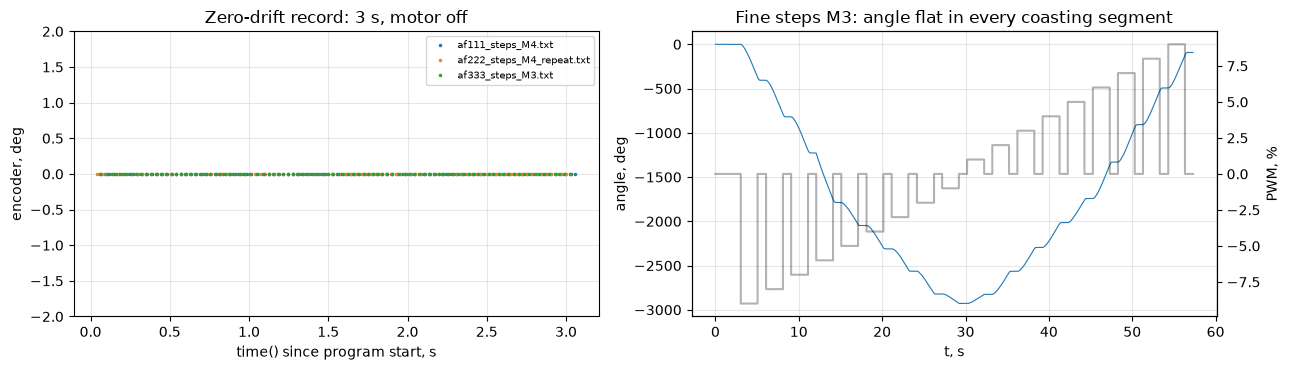

In [13]:
# 2. Zero drift and time offset
zero = []
for f in ("af111_steps_M4.txt", "af222_steps_M4_repeat.txt", "af333_steps_M3.txt", "af888_deadzone_M4.txt", "af999_deadzone_M3.txt"):
    t, th, u, t_first = load_log(f)
    z = t < 3.0
    zero.append(dict(file=f, first_time_ms=t_first, samples_in_zero_block=z.sum(),
                     angle_change_deg=np.degrees(th[z].max() - th[z].min())))
for f in ("af444_square_M4.txt", "af555_square_M3.txt", "af666_chirp_M4.txt", "af777_chirp_M3.txt", "af999_deadzone_M3.txt"):
    t, th, u, t_first = load_log(f)
    zero.append(dict(file=f, first_time_ms=t_first, final_angle_deg=np.degrees(th[-1]),
                     last_second_change_deg=np.degrees(th[-1] - th[t > t[-1] - 0.5][0])))
display(pd.DataFrame(zero).set_index("file").round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for f in ("af111_steps_M4.txt", "af222_steps_M4_repeat.txt", "af333_steps_M3.txt"):
    t, th, u, t_first = load_log(f)
    ax[0].plot(t + t_first / 1000, np.degrees(th), ".", ms=3, label=f)
ax[0].set_xlabel("time() since program start, s"); ax[0].set_ylabel("encoder, deg"); ax[0].set_ylim(-2, 2)
ax[0].set_title("Zero-drift record: 3 s, motor off"); ax[0].legend(fontsize=7)
t, th, u, _ = load_log("af999_deadzone_M3.txt")
ax[1].plot(t, np.degrees(th), lw=0.8); ax[1].set_xlabel("t, s"); ax[1].set_ylabel("angle, deg")
a2 = ax[1].twinx(); a2.step(t, u, "k", where="post", alpha=0.3); a2.set_ylabel("PWM, %"); a2.grid(False)
ax[1].set_title("Fine steps M3: angle flat in every coasting segment")
plt.tight_layout(); plt.show()

*Figure 7. **No zero drift:** the encoder stays at 0° with the motor off. The first sample comes 45–100 ms after the program starts.*

In [14]:
# 3. Dead zone and PWM resolution, 4. saturation
display(fine.pivot(index="pwm", columns="motor", values="omega").round(2).T)
sat = []
for (m, side), L in lines.items():
    sgn = 1 if side == "fwd" else -1
    d = fits[(fits.motor == m) & (sgn * fits.pwm >= 70)]
    s_hi = np.polyfit(d.pwm, d.omega_ss, 1)[0]
    sat.append(dict(motor=m, direction=side, slope_10_70=L["slope"], slope_70_100=s_hi, change_pct=100 * (s_hi - L["slope"]) / L["slope"],
                    omega_at_5=fits[(fits.motor == m) & (fits.pwm == 5 * sgn)].omega_ss.iloc[0],
                    line_at_5=L["slope"] * 5 * sgn + L["intercept"]))
pd.DataFrame(sat).set_index(["motor", "direction"]).round(3)

pwm,-9,-8,-7,-6,-5,-4,-3,-2,-1,1,2,3,4,5,6,7,8,9
motor,,,,,,,,,,,,,,,,,,
M3,-3.92,-4.03,-4.03,-4.26,-2.61,-2.66,-2.74,-2.48,-1.13,1.04,2.61,2.67,2.75,2.72,4.01,4.07,3.97,3.92
M4,-2.68,-2.76,-2.77,-2.79,-1.76,-1.77,-1.80,-1.88,-0.87,0.98,1.88,1.97,1.94,1.95,2.91,2.88,2.86,2.93


slope_10_70  slope_70_100  change_pct  omega_at_5  line_at_5
motor direction                                                              
M3    fwd              0.118         0.101     -14.669       2.998      5.999
      bwd              0.114         0.104      -8.643      -3.188     -5.625
M4    fwd              0.123         0.138      11.862       2.171      4.257
      bwd              0.108         0.114       5.284      -2.246     -4.611

**Dead zone:** < 1 % (the wheel turns at ±1 %). **Saturation:** none; speed keeps rising up to 100 %.

In [15]:
# 5. Coasting after power-off: fine-step run on M3 (1 s logged after each level)
t, th, u, _ = load_log("af999_deadzone_M3.txt")
coast = []
for lv in [l for l in range(-9, 10) if l != 0]:
    on = np.where(u == lv)[0]
    off = np.arange(on[-1] + 1, min(on[-1] + 40, len(u)))
    off = off[u[off] == 0]
    w_end = np.polyfit(t[on[-6:]], th[on[-6:]], 1)[0]
    tm = wss_B(lv, "M3")[1]
    coast.append(dict(pwm=lv, speed_at_off_rad_s=w_end, coast_angle_deg=np.degrees(th[off[-1]] - th[on[-1]]),
                      model_coast_deg=np.degrees(w_end * tm), T_m_model_s=tm))
coast = pd.DataFrame(coast).set_index("pwm")
display(coast.round(2).T)
for key in ("square M4", "square M3", "chirp M4", "chirp M3"):
    d = meas[key]; i = np.where(d["u"] != 0)[0][-1]
    y = sims[(key, "C (refit on square)")]
    print(f"{key}: coasting after power-off measured {np.degrees(d['th'][-1] - d['th'][i]):6.1f} deg, "
          f"model C {np.degrees(y[-1, 1] - y[i, 1]):6.1f} deg")

pwm,-9,-8,-7,-6,-5,-4,-3,-2,-1,1,2,3,4,5,6,7,8,9
speed_at_off_rad_s,-4.07,-4.18,-4.12,-4.21,-2.75,-2.65,-2.72,-2.59,-1.13,1.11,2.74,2.82,2.77,2.80,4.16,4.10,4.03,4.02
coast_angle_deg,-44.00,-42.00,-45.00,-48.00,-21.00,-20.00,-23.00,-16.00,-6.00,4.00,23.00,23.00,20.00,23.00,44.00,45.00,42.00,42.00
model_coast_deg,-114.53,-128.76,-137.97,-152.05,-106.83,-99.79,-98.95,-91.30,-38.30,35.01,83.16,82.21,77.60,74.90,110.21,107.14,103.86,102.36
T_m_model_s,0.49,0.54,0.58,0.63,0.68,0.66,0.64,0.61,0.59,0.55,0.53,0.51,0.49,0.47,0.46,0.46,0.45,0.44


square M4: coasting after power-off measured -148.0 deg, model C  -80.9 deg
square M3: coasting after power-off measured -219.0 deg, model C -109.2 deg
chirp M4: coasting after power-off measured   -2.0 deg, model C    1.5 deg
chirp M3: coasting after power-off measured  -12.0 deg, model C  -18.8 deg


**Coasting:** after power-off the wheel slows at an almost constant rate (friction), not exponentially. It coasts less than the model at low speed and about 2× more at ±60 %.

In [16]:
# 6. Gear backlash: time from each command reversal to the angle turning point, measured vs model C
bl = []
for key in ("square M4", "square M3"):
    d = meas[key]; y = sims[(key, "C (refit on square)")]
    rev = np.where(np.diff(np.sign(d["u"])) != 0)[0] + 1
    rev = rev[(d["u"][rev] != 0) & (d["u"][rev - 1] != 0)]
    for r in rev[:-1]:
        seg = slice(r, r + 10)
        sgn = np.sign(d["u"][r])
        i_m = r + np.argmin(sgn * d["th"][seg]); i_s = r + np.argmin(sgn * y[seg, 1])
        flat = np.sum(np.diff(d["th"][r:r + 6]) == 0)
        bl.append(dict(run=key, delay_meas_ms=1000 * (d["t"][i_m] - d["t"][r]), delay_model_ms=1000 * (d["t"][i_s] - d["t"][r]),
                       flat_samples=flat))
bl = pd.DataFrame(bl)
bl.groupby("run").agg(["mean", "std", "max"]).round(1)

delay_meas_ms             delay_model_ms             flat_samples  \
                   mean   std   max           mean   std   max         mean   
run                                                                           
square M3          81.3  19.5  96.7           90.7   7.3  96.7          0.1   
square M4          57.2  17.1  95.3           90.7  11.5  97.8          0.2   

                    
           std max  
run                 
square M3  0.4   1  
square M4  0.4   1

**Backlash:** none visible. The angle reverses on time, with no flat samples.

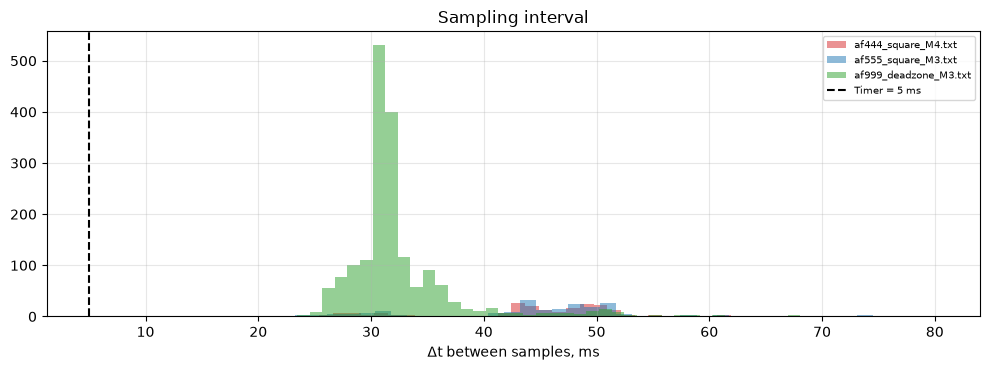

,mean_ms,min_ms,max_ms,std_ms
file,,,,
af444_square_M4.txt,45.0,24.2,72.8,8.4
af555_square_M3.txt,45.3,23.2,80.2,9.1
af999_deadzone_M3.txt,32.4,23.5,68.1,5.0
week5_steps (all),10.0,7.0,37.0,2.3


In [17]:
# 7. Sampling jitter
fig, ax = plt.subplots(figsize=(10, 3.8))
jit = []
for f, c in (("af444_square_M4.txt", "tab:red"), ("af555_square_M3.txt", "tab:blue"), ("af999_deadzone_M3.txt", "tab:green")):
    t, th, u, _ = load_log(f); dt = np.diff(t) * 1000
    ax.hist(dt, bins=40, alpha=0.5, color=c, label=f)
    jit.append(dict(file=f, mean_ms=dt.mean(), min_ms=dt.min(), max_ms=dt.max(), std_ms=dt.std()))
dtw = np.concatenate([np.diff(r["t"]) * 1000 for r in week5])
jit.append(dict(file="week5_steps (all)", mean_ms=dtw.mean(), min_ms=dtw.min(), max_ms=dtw.max(), std_ms=dtw.std()))
ax.axvline(5, color="k", ls="--", label="Timer = 5 ms"); ax.set_xlabel("Δt between samples, ms"); ax.legend(fontsize=7)
ax.set_title("Sampling interval"); plt.tight_layout(); plt.show()
pd.DataFrame(jit).set_index("file").round(1)

*Figure 8. Sampling interval ≈ 30–45 ms (range 23–80 ms), not 5 ms.*

In [18]:
# 8. Battery sag and day-to-day change
v = pd.DataFrame([dict(motor=r["motor"], pwm=r["pwm"], u_rest=r["u_rest"], u_load=r["u_load"]) for r in week5])
print(f"22 Oct: battery at rest {v.u_rest.min():.3f} ... {v.u_rest.max():.3f} V, under load {v.u_load.min():.3f} ... {v.u_load.max():.3f} V, "
      f"largest rest-load difference {np.max(v.u_rest - v.u_load):.3f} V")
for m in ("M3", "M4"):
    print(f"{m}: |ω| at ±60 %: steps 22 Oct {wss_B(60, m)[0]:.2f} / {-wss_B(-60, m)[0]:.2f} rad/s, "
          f"square wave 27 Oct {60*refit[m][0]:.2f} / {60*refit[m][1]:.2f} rad/s "
          f"({100*(60*refit[m][0]/wss_B(60, m)[0]-1):+.0f} % / {100*(60*refit[m][1]/-wss_B(-60, m)[0]-1):+.0f} %)")

22 Oct: battery at rest 12.038 ... 12.115 V, under load 12.025 ... 12.102 V, largest rest-load difference 0.065 V
M3: |ω| at ±60 %: steps 22 Oct 12.37 / 11.81 rad/s, square wave 27 Oct 10.22 / 10.12 rad/s (-17 % / -14 %)
M4: |ω| at ±60 %: steps 22 Oct 10.94 / 10.46 rad/s, square wave 27 Oct 9.43 / 9.19 rad/s (-14 % / -12 %)


**Battery:** stable within 0.1 V on 22 Oct. On 27 Oct the motors were 12–17 % slower, most likely a lower battery (not recorded).

In [19]:
# 9. Encoder quantisation and differentiation noise (steady part of the 22 Oct step at +50 %, and square-wave plateaus)
r = [r for r in week5 if r["motor"] == "M3" and r["pwm"] == 50][0]
k = r["t"] > 1.0
w_raw = np.gradient(r["theta"], r["t"])[k]
noise = dict(raw_std=w_raw.std(), smooth3_std=smooth(np.gradient(r["theta"], r["t"]))[k][1:-1].std(),
             smooth9_std=smooth(np.gradient(r["theta"], r["t"]), 9)[k][4:-4].std())
print("encoder resolution: 1 deg =", round(np.radians(1), 4), "rad; all logged angles are whole degrees:",
      all(np.allclose(np.degrees(meas[x]["th"]), np.round(np.degrees(meas[x]["th"]))) for x in meas))
print(f"one count per sample = {np.radians(1)/0.010:.2f} rad/s at 10 ms, {np.radians(1)/0.045:.2f} rad/s at 45 ms")
print("speed noise in steady state, M3 +50 % (rad/s):", {kk: round(vv, 3) for kk, vv in noise.items()})

encoder resolution: 1 deg = 0.0175 rad; all logged angles are whole degrees: True
one count per sample = 1.75 rad/s at 10 ms, 0.39 rad/s at 45 ms
speed noise in steady state, M3 +50 % (rad/s): {'raw_std': np.float64(1.891), 'smooth3_std': np.float64(1.385), 'smooth9_std': np.float64(0.811)}


**Encoder noise:** 1° resolution makes the raw speed noisy (std 1.9 rad/s); a 3-point average lowers it to 1.4 rad/s.

In [20]:
# 10. Motor-to-motor spread
spread = []
for side in ("fwd", "bwd"):
    a, b = lines[("M3", side)], lines[("M4", side)]
    sgn = 1 if side == "fwd" else -1
    spread.append(dict(direction=side, k_e_M3=a["k_e"], k_e_M4=b["k_e"],
                       omega60_M3=abs(wss_B(60 * sgn, "M3")[0]), omega60_M4=abs(wss_B(60 * sgn, "M4")[0]),
                       omega60_diff_pct=100 * (abs(wss_B(60 * sgn, "M4")[0]) / abs(wss_B(60 * sgn, "M3")[0]) - 1),
                       T_m_M3=a["T_m_mean"], T_m_M4=b["T_m_mean"],
                       omega5_M3=abs(wss_B(5 * sgn, "M3")[0]), omega5_M4=abs(wss_B(5 * sgn, "M4")[0])))
pd.DataFrame(spread).set_index("direction").T.round(3)

direction,fwd,bwd
k_e_M3,1.024,1.059
k_e_M4,0.980,1.114
omega60_M3,12.369,11.815
omega60_M4,10.945,10.458
omega60_diff_pct,-11.514,-11.487
T_m_M3,0.229,0.227
T_m_M4,0.177,0.179
omega5_M3,2.998,3.188
omega5_M4,2.171,2.246


**Left vs right:** M4 is ≈ 11.5 % slower than M3 at ±60 % and has a shorter $T_m$.

## 6. Results and analysis

### Estimated values

In [21]:
for m in ("M3", "M4"):
    tab = []
    for side, name in (("fwd", "Forward"), ("bwd", "Backward")):
        L = lines[(m, side)]
        tab.append({"Direction": name, "Dead zone, % PWM": "< 1", "Slope, rad/s per % PWM": round(L["slope"], 4),
                    "k_e, V·s/rad": round(L["k_e"], 3), "Mean T_m, s": round(L["T_m_mean"], 3), "U_battery, V": round(U_BAT, 2)})
    print(f"Motor {m} ({'right' if m == 'M3' else 'left'} wheel)")
    display(pd.DataFrame(tab).set_index("Direction"))

Motor M3 (right wheel)


,"Dead zone, % PWM","Slope, rad/s per % PWM","k_e, V·s/rad","Mean T_m, s","U_battery, V"
Direction,,,,,
Forward,< 1,0.118,1.024,0.229,12.08
Backward,< 1,0.114,1.059,0.227,12.08


Motor M4 (left wheel)


,"Dead zone, % PWM","Slope, rad/s per % PWM","k_e, V·s/rad","Mean T_m, s","U_battery, V"
Direction,,,,,
Forward,< 1,0.123,0.980,0.177,12.08
Backward,< 1,0.108,1.114,0.179,12.08


### Model quality

Each single step fits well, but $T_m$ and the speed gain change with PWM, so one constant model does not fit everything. On the complex signals model A reaches **58–71 %** speed fit. Even model C (refitted) reaches only **81–83 %** on the square wave and **61–64 %** on the chirp, so the error comes from the model itself. The largest errors are on the plateaus (different battery), after power-off (friction) and at high chirp frequencies.

### Forward vs backward

Nearly the same motor: $T_m$ is equal and forward is ≈ 5 % faster. A controller can use one $T_m$ but should use separate gains for each direction.

### Artifacts that matter for odometry

No encoder drift and no dead zone. Important: **M4 is ≈ 11.5 % slower than M3** (the robot curves), the direction asymmetry, the battery effect (12–17 %), and the slow, uneven sampling.

### Chosen signals

**Square wave:** $T_m$ when reversing (0.11–0.13 s), no backlash, coasting. **Chirp:** the motor acts as a low-pass filter.

### Limitations

The block-program step runs saved only the zero block, so the step series is from 22 Oct and repeatability could not be checked. The battery was not noted on 27 Oct.